In [8]:
from qiskit import QuantumCircuit
from qiskit_aer import AerSimulator
from qiskit.circuit.library import PhaseGate, QFTGate

import numpy as np

In [3]:
m = 3  # number of counting qubits

In [12]:
# I choose phase gate for the unitary U, that I want to estimate
U = PhaseGate(3 * np.pi / 4)

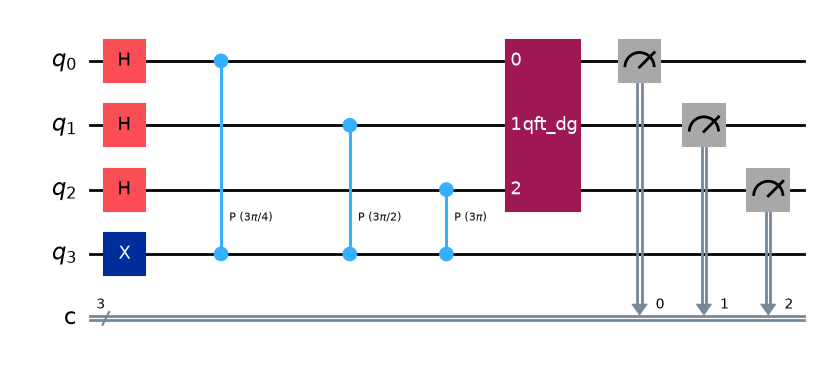

In [20]:
qc = QuantumCircuit(m + 1, m)

qc.h(range(m))

# Eigenstate of phase gate
qc.x(m)

# Apply C-U^(2^j)
for j in range(m):
    controlled_U_power = U.power(2**j).control(1)
    qc.append(controlled_U_power, [j, m])

qc.append(QFTGate(m).inverse(), range(m))

qc.measure(range(m), range(m))

qc.draw("mpl")

Counts: {'011': 1024}
First 10 individual outcomes: ['011', '011', '011', '011', '011', '011', '011', '011', '011', '011']

Outcome   Count   Frequency   Phase φ   Angle θ (rad)
    011    1024     100.00%    0.3750          2.3562


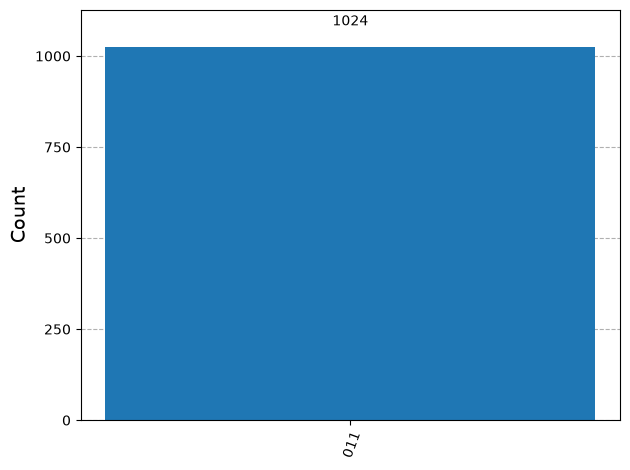

In [21]:
from qiskit import transpile
from qiskit_aer import AerSimulator
from qiskit.visualization import plot_histogram
import numpy as np

simulator = AerSimulator()
compiled_qc = transpile(qc, simulator)

shots = 1024
result = simulator.run(
    compiled_qc,
    shots=shots,
    memory=True,
    seed_simulator=42,
).result()

counts = result.get_counts()
outcomes = result.get_memory()

print("Counts:", counts)
print("First 10 individual outcomes:", outcomes[:10])

print("\nOutcome   Count   Frequency   Phase φ   Angle θ (rad)")
for bitstring, count in sorted(
    counts.items(), key=lambda item: item[1], reverse=True
):
    y = int(bitstring, 2)
    phase = y / (2**m)
    angle = 2 * np.pi * phase

    print(
        f"{bitstring:>7}   {count:>5}   {count/shots:>9.2%}"
        f"   {phase:>7.4f}   {angle:>13.4f}"
    )

plot_histogram(counts)